# NB08 — Musanga satellite detectability | V4 native-reference rebuild

**Scientific target:** upscale NB07 V4 UAV-derived Musanga probability / fractional cover to satellite predictors. This notebook is a **clean V4 replacement**, not a continuation of the V3_1 satellite analysis.

- **UAV target:** six V4 NB07 georeferenced two-band mosaics (band 1 probability, band 2 binary at p≥0.5). The mosaics are already clipped by the NB07 ROI100 + RGB/DSM/MS validity policy. Values outside it remain NoData.
- **Satellite inputs:** existing source *raster products* only: annual Sentinel-2, annual embeddings, and three-year quarterly Sentinel-2. These can reside in the legacy `Outputs/V3_1/04_satellite_predictors/input_layers` input directory; **no V3_1 samples, targets, models, metrics, maps, or conclusions are imported**.
- **Primary validation:** strict leave-one-**forest**-out (Baego, MOS, Yangambi, Yoko), pooled MOS flight groups as one held-out forest. Equal-forest training and equal-forest reporting.
- **Scale comparison:** 50, 100, 125 m by default; 30 m may be added as an exploratory sensitivity test.
- **Interpretation:** compare source-derived satellite predictor families and explicitly report MOS >40% cover saturation. Site-holdout transfer may remain poor even if spatially held-out within-site skill is useful.
- **No Earth Engine exports or whole-region inference** in this validation notebook; do not claim an operational Kisangani map from these tests.

Run **00 → 04** in CPU Colab. Products are versioned under `Final/Outputs/v4/08_satellite_detectability_new_uav`. Input data are never overwritten. Sampling is cached for resumability. The previous notebook outputs are not reused.


## 00 — Settings
The 2020 Yoko satellite window follows the *available three-year raster product*, which must be checked against the actual Yoko UAV acquisition year before biological interpretation. Do not silently substitute 2021 products. Site/year matching is audited in Section 01.


In [3]:
# ====================== USER SETTINGS ======================
SCALES_M = [50,100,125]   # add 30 only after checking 50 m
MAX_CELLS_PER_MOSAIC = 260
MAX_TRIALS_PER_MOSAIC = 2600
MIN_UAV_VALID_FRACTION = 0.90
SATELLITE_LOCAL_STAGE = True
LOCAL_STAGE_MAX_FRACTION_OF_FREE_DISK = .65
SEED = 20261122
MODEL_ITERATIONS = 180
TRAIN_CAP_PER_FOREST = 500
HIGH_COVER = 0.40
FEATURE_SETS = {
    'EMBEDDING': ['EMB_ANNUAL'],
    'S2_ANNUAL': ['RAW_ANNUAL'],
    'S2_SEASONAL': ['S2_QUARTERLY_3YR'],
    'EMB_PLUS_ANNUAL': ['EMB_ANNUAL','RAW_ANNUAL'],
    'EMB_PLUS_SEASONAL': ['EMB_ANNUAL','S2_QUARTERLY_3YR'],
    'ALL': ['EMB_ANNUAL','RAW_ANNUAL','S2_QUARTERLY_3YR'],
}
RUN_MODELS = True
FORCE_SAMPLES = False
# ==========================================================


## 01 — Audit six V4 UAV mosaics and independent satellite raster inputs
This is a hard-stop audit: required input layers, years, CRS, band count, finite valid-value coverage and output metadata must be consistent. Source rasters are staged to local SSD **one forest at a time**, only if there is room. No fallback to V3_1 target tables.


In [4]:
%pip -q install rasterio pandas pyarrow scikit-learn matplotlib scipy
from pathlib import Path
from contextlib import ExitStack
from rasterio.windows import from_bounds,Window
from rasterio.enums import Resampling
import rasterio,numpy as np,pandas as pd
import hashlib,json,shutil,os,math,time
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score
from IPython.display import display
from google.colab import drive
if not Path('/content/drive/MyDrive').exists(): drive.mount('/content/drive')
FINAL=next((p for p in [
    Path('/content/drive/MyDrive/Colab Notebooks/Musanga/Final'),
    Path('/content/drive/MyDrive/Musanga/Final')] if p.is_dir()),None)
assert FINAL is not None,'Musanga/Final folder unavailable'
V4=FINAL/'Outputs/v4'
OUT=V4/'08_satellite_detectability_new_uav'
OUT.mkdir(parents=True,exist_ok=True)
UAV=V4/'07_RGB_MS_100m_ROI_complete_sensors_v4/reconstructed_mosaics'
SAT=FINAL/'Outputs/V3_1/04_satellite_predictors/input_layers'
assert SAT.is_dir(),f'Satellite source raster collection absent: {SAT}'
FORESTS=['Baego','MOS','Yangambi','Yoko']
GROUPS={
 'Baego':['Baego'],
 'MOS':['Mos_1_2_transparent_mosaic_group1_georef',
        'Mos_3_4_transparent_mosaic_group1_georef',
        'Mos_5_6_transparent_mosaic_group1_georef'],
 'Yangambi':['Yangambi_georef'],
 'Yoko':['Yoko_kvo_georef'],
}
YEARS={'Baego':2023,'MOS':2024,'Yangambi':2024,'Yoko':2020}
WINDOWS={'Baego':(2021,2023),'MOS':(2022,2024),
         'Yangambi':(2022,2024),'Yoko':(2018,2020)}
FAMILIES=['EMB_ANNUAL','RAW_ANNUAL','S2_QUARTERLY_3YR']
uav_paths={group:UAV/f'{group}_Musanga_probability_binary_v4.tif'
           for groups in GROUPS.values() for group in groups}
def satellite_name(site,family):
 if family=='S2_QUARTERLY_3YR':
  a,b=WINDOWS[site]
  return f'{site}_S2_QUARTERLY_3YR_{a}_{b}_10m.tif'
 return f'{site}_{family}_{YEARS[site]}_10m.tif'
sat_paths={(site,fam):SAT/fam/satellite_name(site,fam)
           for site in FORESTS for fam in FAMILIES}
records=[]
for group,p in uav_paths.items():
 assert p.is_file(),f'Missing V4 UAV mosaic: {p}'
 with rasterio.open(p) as ds:
  assert ds.count==2 and ds.nodata==-9999 and ds.crs is not None,(group,ds.count,ds.nodata)
  assert all(t=='float32' for t in ds.dtypes),(group,ds.dtypes)
  records.append(dict(type='UAV V4',site=group,bands=ds.count,
                      width=ds.width,height=ds.height,crs=str(ds.crs),size_MB=round(p.stat().st_size/1e6)))
for (site,fam),p in sat_paths.items():
 assert p.is_file(),f'Missing source satellite raster: {p}'
 with rasterio.open(p) as ds:
  assert ds.crs is not None and ds.count>0,(site,fam)
  records.append(dict(type=fam,site=site,bands=ds.count,
                      width=ds.width,height=ds.height,crs=str(ds.crs),size_MB=round(p.stat().st_size/1e6)))
display(pd.DataFrame(records))
print('Yoko satellite reference year:',YEARS['Yoko'],
      '— verify acquisition alignment before interpretation')
print('V4-only target directory:',OUT)


Mounted at /content/drive


,type,site,bands,width,height,crs,size_MB
0,UAV V4,Baego,2,86528,58112,EPSG:32635,253
1,UAV V4,Mos_1_2_transparent_mosaic_group1_georef,2,61696,20480,EPSG:32635,3309
2,UAV V4,Mos_3_4_transparent_mosaic_group1_georef,2,50688,22528,EPSG:32635,2481
3,UAV V4,Mos_5_6_transparent_mosaic_group1_georef,2,20224,24064,EPSG:32635,1143
4,UAV V4,Yangambi_georef,2,42752,24576,EPSG:32635,864
5,UAV V4,Yoko_kvo_georef,2,26112,18688,EPSG:32635,572
6,EMB_ANNUAL,Baego,64,721,491,EPSG:32635,18
7,RAW_ANNUAL,Baego,15,721,491,EPSG:32635,11
8,S2_QUARTERLY_3YR,Baego,44,721,491,EPSG:32635,42
9,EMB_ANNUAL,MOS,64,784,913,EPSG:32635,78


Yoko satellite reference year: 2020 — verify acquisition alignment before interpretation
V4-only target directory: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/v4/08_satellite_detectability_new_uav


## 02 — Build georeferenced V4 samples at multiple physical supports

Sampling grids are anchored to projected map coordinates, not to mosaic-array indices. Randomly selected grid cells must pass the **native UAV NoData coverage** threshold and all three satellite-family validity checks. A missing valid pixel is never treated as absence. Per-scale samples are cached with an input-identity fingerprint. Sampling is intentionally capped per *mosaic* and forest-balanced when fitting. Report low prevalence and high-cover counts before interpreting LOSO metrics.

**Performance note:** UAV reads are local-window reads from the completed V4 mosaics, not a full mosaic load; satellite layers are copied once per forest to local SSD when feasible. Expected time depends on mounted Drive read caching.

**Sampling correction (22 Nov 2026):** At larger cell sizes, random bounding-box proposals can yield very few valid observations. The revised sampler seeds coarse grid candidates near previously valid finer-scale V4 UAV cells, without using labels to select high-cover cases. These are candidate locations, *not* synthetic data. The test now requires ≥30 observed cells per held-out forest; underpowered forests are flagged and omitted from four-forest macro comparisons. Cached validation outputs are saved after each individual fit.


In [5]:
from rasterio.warp import transform_bounds
from rasterio.vrt import WarpedVRT
from rasterio.windows import bounds as window_bounds
LOCAL=Path('/content/musanga_nb08_satellite')
LOCAL.mkdir(parents=True,exist_ok=True)
def input_fingerprint():
 h=hashlib.sha256()
 for p in list(uav_paths.values())+list(sat_paths.values()):
  st=p.stat()
  h.update(f'{p}/{st.st_size}/{st.st_mtime_ns}\n'.encode())
 h.update(json.dumps(dict(scales=SCALES_M,max_cells=MAX_CELLS_PER_MOSAIC,
    trials=MAX_TRIALS_PER_MOSAIC,valid=MIN_UAV_VALID_FRACTION,seed=SEED),sort_keys=True).encode())
 return h.hexdigest()[:20]
KEY=input_fingerprint()
def staged_sources(site):
 # Staging only reusable original satellite rasters. Never stage V3 targets/models.
 original={f:sat_paths[(site,f)] for f in FAMILIES}
 if not SATELLITE_LOCAL_STAGE:return original
 size=sum(p.stat().st_size for p in original.values())
 free=shutil.disk_usage(LOCAL).free
 if size>free*LOCAL_STAGE_MAX_FRACTION_OF_FREE_DISK:
  print(f'[{site}] Insufficient local space ({size/1e9:.1f} GB); using Drive source rasters')
  return original
 site_dir=LOCAL/site
 site_dir.mkdir(parents=True,exist_ok=True)
 result={}
 for fam,p in original.items():
  dest=site_dir/p.name
  if not dest.exists() or dest.stat().st_size!=p.stat().st_size:
   if dest.exists():dest.unlink()
   print(f'[{site}] Stage {fam}: {p.stat().st_size/1e6:.0f} MB',flush=True)
   tmp=dest.with_name(dest.name+'.copying')
   tmp.unlink(missing_ok=True)
   shutil.copyfile(p,tmp)
   assert tmp.stat().st_size==p.stat().st_size
   os.replace(tmp,dest)
  result[fam]=dest
 return result
def raster_mean(ds,bounds):
 # Out-of-bounds satellite support and missing bands are rejected, not zero-filled.
 l,b,r,t=bounds
 if not (ds.bounds.left<=l and ds.bounds.right>=r and
         ds.bounds.bottom<=b and ds.bounds.top>=t):return None
 win=from_bounds(l,b,r,t,transform=ds.transform)
 win=win.round_offsets().round_lengths()
 if win.width<=0 or win.height<=0:return None
 arr=ds.read(window=win,masked=True)
 if np.ma.is_masked(arr):
  fraction=np.mean(~np.ma.getmaskarray(arr).reshape(arr.shape[0],-1),axis=1)
  if np.any(fraction<.85):return None
  data=arr.mean(axis=(1,2)).filled(np.nan)
 else:data=arr.mean(axis=(1,2))
 return np.asarray(data,dtype=np.float32) if np.isfinite(data).all() else None
def uav_target(ds,bounds):
 l,b,r,t=bounds
 if not (ds.bounds.left<=l and ds.bounds.right>=r and
         ds.bounds.bottom<=b and ds.bounds.top>=t):return None
 win=from_bounds(l,b,r,t,transform=ds.transform)
 # Keep precise coverage; cap memory per native-resolution sample.
 win=win.round_offsets().round_lengths()
 if win.width<=0 or win.height<=0:return None
 # Average to a fixed 256x256 support without allocating the full
 # native UAV cell; this is essential at 100–125 m (many million RGB pixels).
 arr=ds.read([1,2],window=win,out_shape=(2,256,256),
             resampling=Resampling.average,masked=True)
 mask=ds.read_masks(1,window=win,out_shape=(256,256),
                    resampling=Resampling.average)
 valid_fraction=float(np.mean(mask.astype(np.float32)/255.))
 if valid_fraction<MIN_UAV_VALID_FRACTION:return None
 valid=~np.ma.getmaskarray(arr[0])
 if not valid.any():return None
 a=np.asarray(arr[0])[valid];b=np.asarray(arr[1])[valid]
 if not (np.isfinite(a).all() and np.isfinite(b).all()):return None
 if not ((a>=0).all() and (a<=1).all() and (b>=0).all() and (b<=1).all()):return None
 return float(a.mean()),float(b.mean()),valid_fraction
def candidate_centers(bounds,scale,rng,n,anchors=None):
 # Globally anchored grid. For coarse supports, seed candidates near
 # independently validated *smaller-scale UAV cells*, then fill the
 # remaining budget uniformly from the whole mosaic footprint.
 c0=math.ceil(bounds.left/scale);c1=math.floor(bounds.right/scale)-1
 r0=math.ceil(bounds.bottom/scale);r1=math.floor(bounds.top/scale)-1
 if c1<c0 or r1<r0:return []
 candidates=[];seen=set()
 def offer(ix,iy):
  key=(int(ix),int(iy))
  if c0<=key[0]<=c1 and r0<=key[1]<=r1 and key not in seen:
   seen.add(key);candidates.append(key)
 if anchors is not None and len(anchors):
  order=rng.permutation(len(anchors))
  for k in order:
   x,y=anchors[k]
   ix=int(math.floor(x/scale));iy=int(math.floor(y/scale))
   offer(ix,iy)
   for dx,dy in [(1,0),(-1,0),(0,1),(0,-1)]:
    offer(ix+dx,iy+dy)
   if len(candidates)>=n//2:break
 for j in range(n*5):
  if len(candidates)>=n:break
  offer(rng.integers(c0,c1+1),rng.integers(r0,r1+1))
 return [((x+.5)*scale,(y+.5)*scale) for x,y in candidates[:n]]
def seed_anchors(group,scale):
 # Only used to improve spatial hit-rate at coarser resolutions.
 # Original samples were built from V4 UAV mosaics, never V3_1.
 smaller=[f for f in all_scales if int(f.scale_m.iloc[0])<scale]
 if not smaller:return None
 anchor=smaller[-1]
 part=anchor[anchor.group==group]
 if part.empty:return None
 return part[['x_m','y_m']].to_numpy(float)
def sample_group(group,site,scale,satellite):
 rng=np.random.default_rng(SEED+scale*13+sum(ord(c) for c in group))
 rows=[]
 with ExitStack() as stack:
  u=stack.enter_context(rasterio.open(uav_paths[group]))
  # Assert genuine metric support (not geographic degree scales).
  assert u.crs.is_projected and abs(u.transform.a)<scale,(group,u.crs,u.transform)
  readers={}
  for fam,path in satellite.items():
   raw=stack.enter_context(rasterio.open(path))
   if raw.crs!=u.crs:
    readers[fam]=stack.enter_context(WarpedVRT(raw,crs=u.crs,
                     resampling=Resampling.bilinear))
   else:readers[fam]=raw
  points=candidate_centers(u.bounds,scale,rng,MAX_TRIALS_PER_MOSAIC,seed_anchors(group,scale))
  for j,(x,y) in enumerate(points):
   if len(rows)>=MAX_CELLS_PER_MOSAIC:break
   bbox=(x-scale/2,y-scale/2,x+scale/2,y+scale/2)
   target=uav_target(u,bbox)
   if target is None:continue
   feat={fam:raster_mean(ds,bbox) for fam,ds in readers.items()}
   if any(v is None for v in feat.values()):continue
   rec=dict(site=site,group=group,scale_m=scale,x_m=x,y_m=y,
            mean_probability=target[0],cover_fraction_p05=target[1],
            uav_valid_fraction=target[2])
   for fam,v in feat.items():
    for k,value in enumerate(v):
     rec[f'{fam}__{k+1:03d}']=float(value)
   rows.append(rec)
   if len(rows)%100==0:print(f'[{site}/{group} {scale}m] {len(rows)} samples',flush=True)
 print(f'[{group} {scale}m] {len(rows)} valid V4 cells from {len(points)} candidates',flush=True)
 return rows
all_scales=[]
for scale in SCALES_M:
 dest=OUT/f'02_V4_uav_satellite_cells_{scale}m_{KEY}{"_seeded" if scale>=125 else ""}.parquet'
 if dest.exists() and not FORCE_SAMPLES:
  frame=pd.read_parquet(dest)
  print('CACHE HIT',dest.name,len(frame),flush=True)
 else:
  pieces=[]
  for site in FORESTS:
   satellite=staged_sources(site)
   for group in GROUPS[site]:
    pieces+=sample_group(group,site,scale,satellite)
  assert pieces,f'No valid V4 samples at {scale} m'
  frame=pd.DataFrame(pieces)
  assert frame.site.nunique()==4,('Missing site support',scale,frame.site.value_counts())
  frame.to_parquet(dest,index=False)
  print('SAVED',dest,flush=True)
 all_scales.append(frame)
samples=pd.concat(all_scales,ignore_index=True)
summary=samples.groupby(['scale_m','site']).agg(
 n=('mean_probability','size'),mean_prob=('mean_probability','mean'),
 cover_40plus=('mean_probability',lambda x:int((x>=HIGH_COVER).sum())),
 valid_uav=('uav_valid_fraction','mean')).reset_index()
display(summary.round(3))
summary.to_csv(OUT/f'02_V4_support_summary_{KEY}.csv',index=False)


CACHE HIT 02_V4_uav_satellite_cells_50m_bd0a878868f7645d4f33.parquet 1323
CACHE HIT 02_V4_uav_satellite_cells_100m_bd0a878868f7645d4f33.parquet 941
[Baego] Stage EMB_ANNUAL: 18 MB
[Baego] Stage RAW_ANNUAL: 11 MB
[Baego] Stage S2_QUARTERLY_3YR: 42 MB
[Baego 125m] 18 valid V4 cells from 1975 candidates
[MOS] Stage EMB_ANNUAL: 78 MB
[MOS] Stage RAW_ANNUAL: 33 MB
[MOS] Stage S2_QUARTERLY_3YR: 83 MB
[MOS/Mos_1_2_transparent_mosaic_group1_georef 125m] 100 samples
[MOS/Mos_1_2_transparent_mosaic_group1_georef 125m] 200 samples
[Mos_1_2_transparent_mosaic_group1_georef 125m] 260 valid V4 cells from 1121 candidates
[MOS/Mos_3_4_transparent_mosaic_group1_georef 125m] 100 samples
[MOS/Mos_3_4_transparent_mosaic_group1_georef 125m] 200 samples
[Mos_3_4_transparent_mosaic_group1_georef 125m] 260 valid V4 cells from 1122 candidates
[MOS/Mos_5_6_transparent_mosaic_group1_georef 125m] 100 samples
[MOS/Mos_5_6_transparent_mosaic_group1_georef 125m] 200 samples
[Mos_5_6_transparent_mosaic_group1_georef 

,scale_m,site,n,mean_prob,cover_40plus,valid_uav
0,50,Baego,35,0.207,6,0.996
1,50,MOS,780,0.263,158,1.000
2,50,Yangambi,248,0.072,0,0.998
3,50,Yoko,260,0.166,27,0.998
4,100,Baego,34,0.180,6,0.987
5,100,MOS,780,0.258,127,1.000
6,100,Yangambi,47,0.072,0,0.999
7,100,Yoko,80,0.164,6,0.997
8,125,Baego,18,0.157,3,0.983
9,125,MOS,780,0.259,110,0.999


## 03 — Strict leave-one-forest-out: feature ablations and resolution test

All four forests are treated as independent geographic domains. **MOS 1–2, 3–4 and 5–6 are always held out together.** Training is capped at equal numbers per forest. Report balanced R² and MAE as well as per-site errors. A poor MOS high-cover estimate is not rescued by pooled low-cover averages. No V3_1 trained model is imported.


In [6]:
def score(y,p):
 y=np.asarray(y,float);p=np.asarray(p,float);mask=y>=HIGH_COVER
 return dict(n=len(y),R2=float(r2_score(y,p)) if len(y)>1 and np.std(y)>1e-8 else np.nan,
  MAE_pp=float(np.mean(abs(p-y))*100),
  RMSE_pp=float(np.sqrt(np.mean((p-y)**2))*100),
  bias_pp=float(np.mean(p-y)*100),
  high_n=int(mask.sum()),
  high_bias_pp=float(np.mean(p[mask]-y[mask])*100) if mask.any() else np.nan,
  high_MAE_pp=float(np.mean(abs(p[mask]-y[mask]))*100) if mask.any() else np.nan)
def capped_train(frame,fold_seed):
 selected=[]
 for site,chunk in frame.groupby('site',sort=True):
  selected.append(chunk.sample(n=min(TRAIN_CAP_PER_FOREST,len(chunk)),
                              random_state=fold_seed))
 return pd.concat(selected,ignore_index=True)
metrics=[];predictions=[]
CV_CACHE=OUT/f'03_V4_LOSO_checkpoints_{KEY}'
CV_CACHE.mkdir(parents=True,exist_ok=True)
MIN_TEST_N=30
if RUN_MODELS:
 for scale,frame in samples.groupby('scale_m',sort=True):
  for family,groups in FEATURE_SETS.items():
   feature_cols=[c for c in frame.columns if any(c.startswith(f+'__') for f in groups)]
   assert feature_cols,(scale,family)
   for forest in FORESTS:
    train=capped_train(frame[frame.site!=forest],SEED+scale)
    test=frame[frame.site==forest].copy()
    if len(train)<=30 or len(test)<MIN_TEST_N:
     print(f'SKIP underpowered validation: {scale}m / {forest}; '
           f'train={len(train)}, held-out={len(test)} (minimum {MIN_TEST_N})',flush=True)
     continue
    check=CV_CACHE/f'{scale}m_{family}_{forest}'
    metric_file=Path(str(check)+'.json')
    pred_file=Path(str(check)+'.parquet')
    if metric_file.exists() and pred_file.exists():
     metrics.append(json.loads(metric_file.read_text()))
     predictions.append(pd.read_parquet(pred_file))
     print(f'CACHE HIT {scale}m {family} {forest}',flush=True)
     continue
    # Balanced by forest, rather than by MOS mosaic count.
    weights=1/train.site.map(train.site.value_counts()).to_numpy(float)
    weights/=weights.mean()
    model=HistGradientBoostingRegressor(
      max_iter=MODEL_ITERATIONS,learning_rate=.06,max_leaf_nodes=18,
      min_samples_leaf=30,l2_regularization=2,early_stopping=False,
      random_state=SEED+scale)
    model.fit(train[feature_cols].to_numpy(np.float32),
              train.mean_probability.to_numpy(np.float32),sample_weight=weights)
    p=np.clip(model.predict(test[feature_cols].to_numpy(np.float32)),0,1)
    y=test.mean_probability.to_numpy(float)
    result=dict(scale_m=scale,family=family,held_out=forest,**score(y,p))
    metrics.append(result)
    test=test[['site','group','scale_m','x_m','y_m','mean_probability']].copy()
    test['predicted']=p;test['family']=family
    predictions.append(test)
    # Save each forest/feature experiment before proceeding to the next.
    temp=Path(str(pred_file)+'.writing')
    test.to_parquet(temp,index=False)
    os.replace(temp,pred_file)
    temp=Path(str(metric_file)+'.writing')
    temp.write_text(json.dumps(result,indent=2))
    os.replace(temp,metric_file)
    print(f'{scale:3d}m {family:19s} holdout={forest:8s} '
          f'MAE={metrics[-1]["MAE_pp"]:.1f} pp, R2={metrics[-1]["R2"]:.2f}',flush=True)
 results=pd.DataFrame(metrics)
 held=pd.concat(predictions,ignore_index=True)
 results.to_csv(OUT/f'03_V4_LOSO_by_forest_{KEY}.csv',index=False)
 held.to_parquet(OUT/f'03_V4_LOSO_predictions_{KEY}.parquet',index=False)
 macro=results.groupby(['scale_m','family']).agg(
   macro_MAE_pp=('MAE_pp','mean'),
   macro_RMSE_pp=('RMSE_pp','mean'),
   macro_bias_pp=('bias_pp','mean'),
   mean_forest_R2=('R2','mean'),
   high_bias_pp=('high_bias_pp','mean'),
   forests=('held_out','nunique')).reset_index()
 macro['eligible_equal_forest']=macro.forests.eq(4)
 if not macro.eligible_equal_forest.all():
  print('WARNING: underpowered holdouts excluded; rows with fewer than 4 forests are NOT equal-forest benchmarks.')
 macro.to_csv(OUT/f'03_V4_LOSO_equal_forest_{KEY}.csv',index=False)
 display(macro.sort_values(['scale_m','macro_MAE_pp']).round(3))
else:
 print('RUN_MODELS=False: only fresh V4 sampling was performed.')


 50m EMBEDDING           holdout=Baego    MAE=7.6 pp, R2=0.79
 50m EMBEDDING           holdout=MOS      MAE=11.9 pp, R2=0.20
 50m EMBEDDING           holdout=Yangambi MAE=4.7 pp, R2=-0.74
 50m EMBEDDING           holdout=Yoko     MAE=8.7 pp, R2=0.42
 50m S2_ANNUAL           holdout=Baego    MAE=10.8 pp, R2=0.48
 50m S2_ANNUAL           holdout=MOS      MAE=13.6 pp, R2=-0.03
 50m S2_ANNUAL           holdout=Yangambi MAE=4.3 pp, R2=-0.55
 50m S2_ANNUAL           holdout=Yoko     MAE=9.2 pp, R2=0.38
 50m S2_SEASONAL         holdout=Baego    MAE=9.3 pp, R2=0.64
 50m S2_SEASONAL         holdout=MOS      MAE=14.1 pp, R2=-0.14
 50m S2_SEASONAL         holdout=Yangambi MAE=6.3 pp, R2=-1.88
 50m S2_SEASONAL         holdout=Yoko     MAE=9.3 pp, R2=0.35
 50m EMB_PLUS_ANNUAL     holdout=Baego    MAE=8.9 pp, R2=0.68
 50m EMB_PLUS_ANNUAL     holdout=MOS      MAE=12.4 pp, R2=0.15
 50m EMB_PLUS_ANNUAL     holdout=Yangambi MAE=3.8 pp, R2=-0.27
 50m EMB_PLUS_ANNUAL     holdout=Yoko     MAE=8.3 pp, R2=0.

,scale_m,family,macro_MAE_pp,macro_RMSE_pp,macro_bias_pp,mean_forest_R2,high_bias_pp,forests,eligible_equal_forest
1,50,EMBEDDING,8.205,10.453,1.944,0.168,-13.838,4,True
3,50,EMB_PLUS_SEASONAL,8.293,10.857,1.766,0.255,-14.767,4,True
2,50,EMB_PLUS_ANNUAL,8.327,10.878,1.346,0.246,-14.967,4,True
0,50,ALL,8.622,11.321,1.092,0.234,-16.750,4,True
4,50,S2_ANNUAL,9.479,12.277,0.733,0.070,-17.983,4,True
5,50,S2_SEASONAL,9.755,12.443,2.948,-0.256,-12.904,4,True
6,100,ALL,6.749,8.863,2.025,0.194,-13.409,4,True
8,100,EMB_PLUS_ANNUAL,6.846,8.835,2.556,0.122,-11.659,4,True
9,100,EMB_PLUS_SEASONAL,6.853,8.951,2.661,0.048,-12.351,4,True
7,100,EMBEDDING,6.873,8.800,2.740,-0.437,-12.105,4,True


## 04 — Publication-oriented held-out diagnostics
Equal-forest summary, per-forest performance and held-out scatterplots (each forest displayed separately; MOS not allowed to visually dominate the others). Include one-to-one line, 40% cover reference and explicit high-cover sample counts. These are **strict external-forest** predictions, not spatially held-out circles. Re-run only after Section 03.


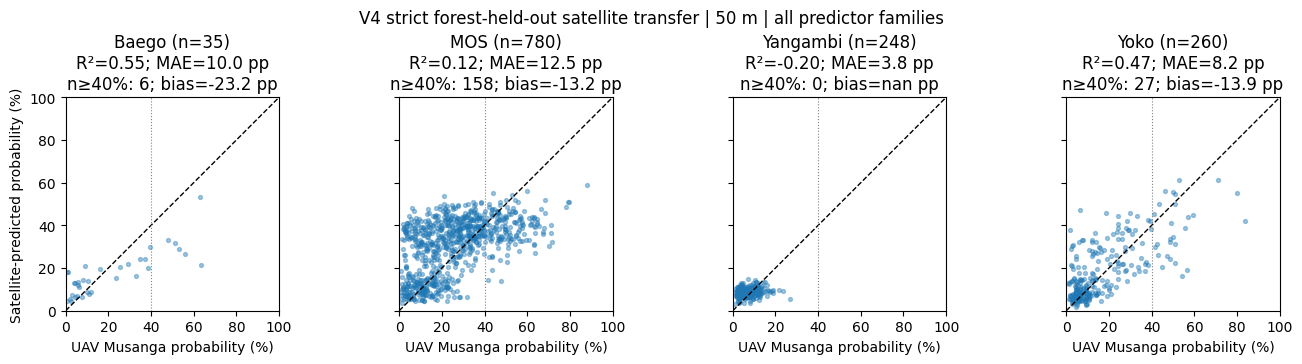

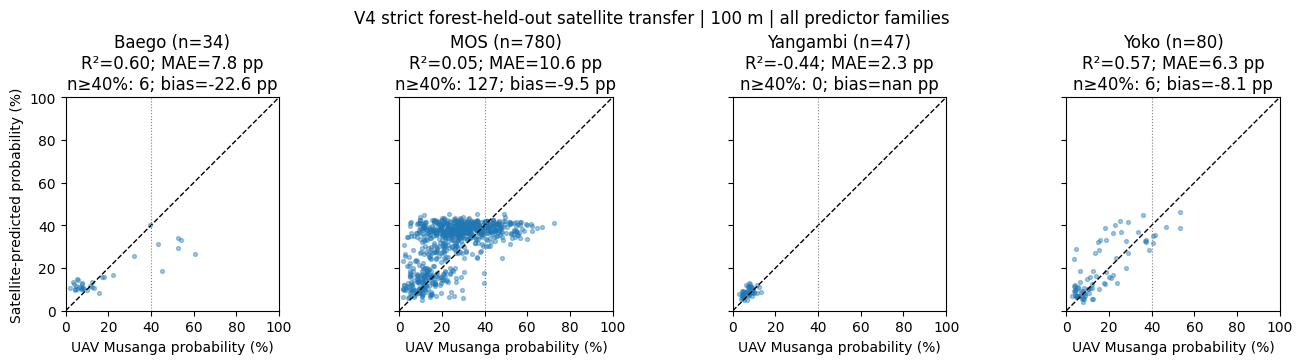

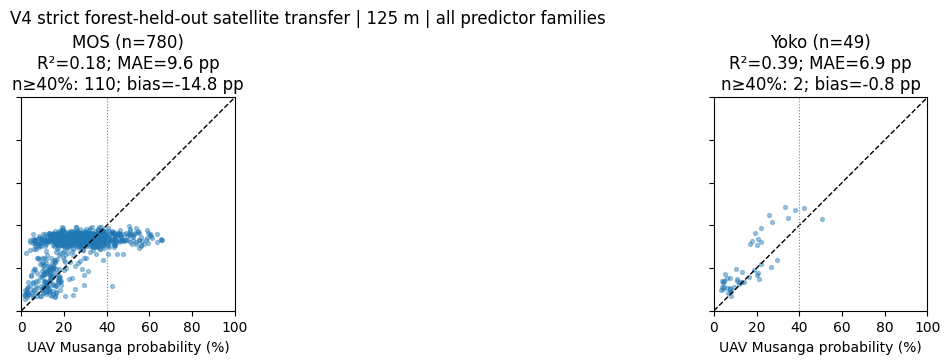

Output: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/v4/08_satellite_detectability_new_uav


In [7]:
if RUN_MODELS:
 import matplotlib.pyplot as plt
 for scale in SCALES_M:
  fig,axes=plt.subplots(1,4,figsize=(14,3.5),sharex=True,sharey=True)
  for ax,site in zip(axes,FORESTS):
   part=held[(held.scale_m==scale)&(held.family=='ALL')&(held.site==site)]
   if part.empty:
    ax.set_visible(False);continue
   ax.scatter(part.mean_probability*100,part.predicted*100,s=8,alpha=.40,rasterized=True)
   ax.plot([0,100],[0,100],c='black',lw=1,ls='--')
   ax.axvline(HIGH_COVER*100,c='gray',lw=.8,ls=':')
   stat=score(part.mean_probability,part.predicted)
   ax.set_title(f'{site} (n={len(part)})\nR²={stat["R2"]:.2f}; MAE={stat["MAE_pp"]:.1f} pp\n'
                f'n≥40%: {stat["high_n"]}; bias={stat["high_bias_pp"]:.1f} pp')
   ax.set_xlim(0,100);ax.set_ylim(0,100);ax.set_aspect('equal')
   ax.set_xlabel('UAV Musanga probability (%)')
  axes[0].set_ylabel('Satellite-predicted probability (%)')
  fig.suptitle(f'V4 strict forest-held-out satellite transfer | {scale} m | all predictor families')
  fig.tight_layout()
  fig.savefig(OUT/f'04_LOSO_scatter_all_{scale}m_{KEY}.png',dpi=180)
  plt.show()
 print('Output:',OUT)


## 05 — V4 replication of yesterday's NB08 detectability contract (primary test)

**Why this exists:** Sections 00–04 are a deliberately limited V4 pilot and are **not directly comparable** to the preceding 44-cell notebook's V3_1 results. The archived notebook used 14,454 target cells at 50 m (Baego 480, MOS 11,494, Yangambi 1,383, Yoko 1,097) versus 1,323 in this new V4 run (35, 780, 248, 260). Its training cap was 1,500 per forest and training draws were abundance-stratified; it excluded quarterly **observation-count** bands from spectral features and evaluated constant null, continuous cover and threshold discrimination separately.

This section restores the **same scientific evaluation definitions** on **V4 UAV-only** reference cells. It does **not** reuse V3_1 models, reference tables or results. As the V4 ROI100 + all-sensor coverage is narrower, it may have fundamentally different abundance support. Report sample sizes and extrapolation limitations; do not compare scores as if they measured a common target domain.

Primary hypothesis: **Does spectral Sentinel-2 contain Musanga-associated information beyond annual embedding features and a constant-abundance baseline?** We use separate bands for reflectance, vegetation indices, pooled quarterly reflectance, and embeddings, with strict leave-one-forest-out evaluation and identical V4 test rows for every feature combination. This is predictive association, not identification of a unique spectral signature.

Run after **02**. Results cached independently under `05_V4_replication`.


In [ ]:
from sklearn.metrics import roc_auc_score,average_precision_score
from scipy.stats import spearmanr
from threadpoolctl import threadpool_limits
threadpool_limits(limits=1)
REPL_SCALES=[s for s in [50,100] if s in set(samples.scale_m)]
REPL_TRAIN_CAP=1500
REPL_THRESHOLDS=[.05,.20,.40]
REPL_DIR=OUT/'05_V4_replication'
REPL_DIR.mkdir(parents=True,exist_ok=True)
# Physically meaningful annual S2 composition (10 reflectances, 4 indices,
# 1 clear-observation count). Quarterly blocks: 10 reflectances + 1 count.
s2_ref=[f'RAW_ANNUAL__{i:03d}' for i in range(1,11)]
s2_idx=[f'RAW_ANNUAL__{i:03d}' for i in range(11,15)]
s2_cnt='RAW_ANNUAL__015'
q_ref=[f'S2_QUARTERLY_3YR__{i:03d}' for i in range(1,45) if i not in [11,22,33,44]]
q_cnt=[f'S2_QUARTERLY_3YR__{i:03d}' for i in [11,22,33,44]]
emb=[f'EMB_ANNUAL__{i:03d}' for i in range(1,65)]
assert set(s2_ref+s2_idx+[s2_cnt]+q_ref+q_cnt+emb).issubset(samples.columns)
REPL_SETS={
 'M0_constant':[],
 'A_S2_reflectance':s2_ref,
 'B_S2_annual_indices':s2_ref+s2_idx,
 'C_S2_quarters':q_ref,
 'D_S2_annual_quarters':s2_ref+s2_idx+q_ref,
 'E_embeddings':emb,
 'F_S2_all_embeddings':s2_ref+s2_idx+q_ref+emb}
REPL_MODEL_ARGS=dict(learning_rate=.06,max_iter=180,max_leaf_nodes=20,
                     min_samples_leaf=35,l2_regularization=2,early_stopping=False)
def stratified_draw_v4(chunk,cap,seed):
 rng=np.random.default_rng(seed)
 if len(chunk)<=cap:return chunk
 y=chunk.mean_probability.to_numpy(float)
 strata=np.digitize(y,[.10,.20,.40])
 available={j:np.flatnonzero(strata==j).tolist() for j in range(4)}
 picked=[]
 high=available[3]
 n=min(len(high),int(np.ceil(.25*cap)))
 if n:
  take=rng.choice(high,n,replace=False).tolist()
  picked.extend(take);available[3]=[i for i in high if i not in set(take)]
 while len(picked)<cap:
  active=[j for j in available if available[j]]
  if not active:break
  for j in active:
   n=min(len(available[j]),max(1,(cap-len(picked))//len(active)),cap-len(picked))
   if n:
    take=rng.choice(available[j],n,replace=False).tolist()
    picked.extend(take)
    chosen=set(take);available[j]=[i for i in available[j] if i not in chosen]
   if len(picked)>=cap:break
 return chunk.iloc[np.sort(picked)].copy()
def v4_metrics(y,p):
 y=np.asarray(y,float);p=np.asarray(p,float)
 err=p-y;v=np.var(y)
 rho=spearmanr(y,p).statistic if np.std(p)>1e-10 and np.std(y)>1e-10 else np.nan
 return dict(R2=float(1-np.mean(err**2)/v) if v>1e-12 else np.nan,
   MAE_pp=float(np.mean(abs(err))*100),RMSE_pp=float(np.sqrt(np.mean(err**2))*100),
   bias_pp=float(np.mean(err)*100),Spearman=float(rho))
repl_rows=[];repl_detect=[];repl_predictions=[]
for scale in REPL_SCALES:
 frame=samples[samples.scale_m==scale].reset_index(drop=True)
 for held in FORESTS:
  test=frame[frame.site==held].copy()
  train=pd.concat([
   stratified_draw_v4(frame[frame.site==f],REPL_TRAIN_CAP,
     SEED+scale+sum(map(ord,held))+sum(map(ord,f)))
   for f in FORESTS if f!=held],ignore_index=True)
  # Identical V4 test rows in all seven variants.
  if len(test)<30:
   print('UNDERPOWERED',scale,held,len(test));continue
  baseline=float(train.mean_probability.mean())
  for model_name,cols in REPL_SETS.items():
   dest=REPL_DIR/f'{KEY}_{scale}m_{held}_{model_name}.parquet'
   if dest.is_file():
    d=pd.read_parquet(dest)
    assert len(d)==len(test)
   else:
    if not cols:p=np.full(len(test),baseline)
    else:
     model=HistGradientBoostingRegressor(random_state=SEED+scale,**REPL_MODEL_ARGS)
     model.fit(train[cols].to_numpy(np.float32),
               train.mean_probability.to_numpy(np.float32))
     p=np.clip(model.predict(test[cols].to_numpy(np.float32)),0,1)
    d=test[['site','group','scale_m','x_m','y_m','mean_probability']].copy()
    d['prediction']=p
    tmp=dest.with_suffix('.partial')
    d.to_parquet(tmp,index=False);os.replace(tmp,dest)
   y=d.mean_probability.to_numpy(float);p=d.prediction.to_numpy(float)
   repl_rows.append(dict(scale_m=scale,held_out=held,model=model_name,
                         n=len(d),**v4_metrics(y,p)))
   repl_predictions.append(d.assign(model=model_name))
   for threshold in REPL_THRESHOLDS:
    event=(y>=threshold).astype(int)
    evaluable=bool(event.min()!=event.max() and np.unique(p).size>1)
    repl_detect.append(dict(scale_m=scale,held_out=held,model=model_name,
      threshold=threshold,n=len(d),n_positive=int(event.sum()),
      prevalence=float(event.mean()),
      AUC=float(roc_auc_score(event,p)) if evaluable else np.nan,
      AP=float(average_precision_score(event,p)) if evaluable else np.nan))
repl_score=pd.DataFrame(repl_rows);repl_disc=pd.DataFrame(repl_detect)
repl_score.to_csv(REPL_DIR/f'05_continuous_by_forest_{KEY}.csv',index=False)
repl_disc.to_csv(REPL_DIR/f'05_detectability_by_forest_{KEY}.csv',index=False)
if not repl_score.empty:
 rep=repl_score.groupby(['scale_m','model']).agg(
  n_forests=('held_out','nunique'),MAE_pp=('MAE_pp','mean'),
  RMSE_pp=('RMSE_pp',lambda s:np.sqrt(np.mean(np.asarray(s)**2))),
  mean_forest_R2=('R2','mean')).reset_index()
 # Correct equal-forest pooled R², not mean of within-forest R².
 for (scale,model),group in pd.concat(repl_predictions,ignore_index=True).groupby(['scale_m','model']):
  mu=np.mean([g.mean_probability.mean() for _,g in group.groupby('site')])
  denominator=np.mean([np.mean((g.mean_probability-mu)**2) for _,g in group.groupby('site')])
  mse=np.mean([np.mean((g.prediction-g.mean_probability)**2) for _,g in group.groupby('site')])
  rep.loc[(rep.scale_m==scale)&(rep.model==model),'equal_forest_R2']=1-mse/denominator
 rep.to_csv(REPL_DIR/f'05_equal_forest_score_{KEY}.csv',index=False)
 display(rep.round(3))
 display(repl_disc.groupby(['scale_m','model','threshold']).agg(
  forests_evaluable=('AUC','count'),mean_AUC=('AUC','mean'),mean_AP=('AP','mean'),
  positives=('n_positive','sum')).round(3))
print('V4 replicated detectability outputs:',REPL_DIR)


## 06 — Physical Sentinel-2 spectral and seasonal contrasts (V4)

Replicates yesterday's **scientific information** test, not just predictive accuracy: compare the physical S2 reflectance curves of V4 cells with ≤5% versus ≥40% Musanga probability. Plot median and IQR across the ten actual S2 bands, then separate three-year pooled quarterly NDVI trends. Forests lacking sufficient low/high observations are explicitly marked non-estimable. These **unmatched** contrasts cannot establish spectral specificity relative to forest condition or other pioneer trees.


In [ ]:
import matplotlib.pyplot as plt
S2_BANDS=['B2','B3','B4','B8','B5','B6','B7','B8A','B11','B12']
S2_WL=np.array([492,560,665,833,704,740,783,865,1610,2190])
order=np.argsort(S2_WL)
fig,axes=plt.subplots(2,2,figsize=(13,9),layout='constrained')
spectral_rows=[]
for ax,site in zip(axes.flat,FORESTS):
 d=samples[(samples.scale_m==50)&(samples.site==site)]
 lo=d[d.mean_probability<=.05];hi=d[d.mean_probability>=.40]
 if len(lo)<10 or len(hi)<10:
  ax.text(.5,.5,f'Insufficient V4 contrast\nlow={len(lo)} high={len(hi)}',
          ha='center',va='center',transform=ax.transAxes)
  ax.set_title(site+' — not estimable');continue
 for part,label in [(lo,'≤5%'),(hi,'≥40%')]:
  arr=part[s2_ref].to_numpy(float)[:,order]
  med=np.median(arr,axis=0);q1=np.percentile(arr,25,axis=0);q3=np.percentile(arr,75,axis=0)
  ax.plot(S2_WL[order],med,'o-',label=f'{label}, n={len(part)}')
  ax.fill_between(S2_WL[order],q1,q3,alpha=.15)
  for j,k in enumerate(order):
   spectral_rows.append(dict(site=site,class_name=label,band=S2_BANDS[k],
        wavelength_nm=int(S2_WL[k]),median=med[j],q25=q1[j],q75=q3[j],n=len(part)))
 ax.set(title=site,xlabel='S2 centre wavelength (nm)',ylabel='Annual reflectance')
 ax.legend();ax.grid(alpha=.15)
fig.suptitle('V4 native-reference annual S2 spectral separability — 50 m')
plt.savefig(REPL_DIR/f'06_V4_S2_spectral_IQR_{KEY}.png',dpi=180)
plt.show()
pd.DataFrame(spectral_rows).to_csv(REPL_DIR/f'06_V4_spectral_IQR_{KEY}.csv',index=False)
fig,axes=plt.subplots(2,2,figsize=(12,8),layout='constrained')
quarter_rows=[]
for ax,site in zip(axes.flat,FORESTS):
 d=samples[(samples.scale_m==50)&(samples.site==site)]
 for cl,subset in [('≤5%',d[d.mean_probability<=.05]),('≥40%',d[d.mean_probability>=.40])]:
  if len(subset)<10:continue
  for q in range(4):
   red=subset[f'S2_QUARTERLY_3YR__{q*11+3:03d}'].to_numpy(float)
   nir=subset[f'S2_QUARTERLY_3YR__{q*11+4:03d}'].to_numpy(float)
   ndvi=(nir-red)/np.maximum(nir+red,1e-8)
   quarter_rows.append(dict(site=site,class_name=cl,quarter=q+1,n=len(subset),
            median=np.median(ndvi),q25=np.percentile(ndvi,25),q75=np.percentile(ndvi,75)))
 qdata=pd.DataFrame(quarter_rows)
 for cl in ['≤5%','≥40%']:
  if qdata.empty:continue
  t=qdata[(qdata.site==site)&(qdata.class_name==cl)].sort_values('quarter')
  if t.empty:continue
  ax.plot(t.quarter,t['median'],'o-',label=cl)
  ax.fill_between(t.quarter.to_numpy(float),t.q25.to_numpy(float),t.q75.to_numpy(float),alpha=.15)
 ax.set(title=site,xlabel='Three-year pooled quarter',ylabel='NDVI from quarter medians',
        xticks=[1,2,3,4])
 ax.legend();ax.grid(alpha=.15)
fig.suptitle('V4 conditional seasonal contrast — not single-year phenology')
plt.savefig(REPL_DIR/f'06_V4_quarterly_NDVI_{KEY}.png',dpi=180)
plt.show()
pd.DataFrame(quarter_rows).to_csv(REPL_DIR/f'06_V4_quarterly_NDVI_{KEY}.csv',index=False)


## 07 — What still must be rebuilt for a truly matched yesterday-versus-today comparison

Yesterday's source teacher contained **14,454** 50-m cells; the new V4 sampling yielded **1,323**, with Baego only 35. The V4 inference footprint is restricted to all-sensor ROI100 support, rather than the old V3_1 teacher footprint. The new sampler is also capped at 260 per mosaic and randomly proposes cells from mosaic bounding boxes. The 50 m/100 m scale comparison changes both target support and sample allocation. Consequently, **the old S2 superiority cannot be confirmed or rejected from these current V4 scores**.

Next pipeline step (not silently approximated here): rasterize the exact V4 valid-support mask and enumerate *all* or spatially representative occupied 10-m / 30-m / 50-m / 75-m / 100-m grid cells using area-weighted UAV probability and satellite reflectance, with coverage fractions. Audit original UAV dates and satellite-year matching. Repeat strict forest holdouts with equal training caps, independent validation cells and 500-m spatial-block bootstrap.

Yesterday's forest-height, tree-cover, disturbance and balance-gated B8 spectral matching tests depended on **separately sourced forest-condition rasters on the old support**. Those controls must be spatially sampled again onto the new V4 cells; they are **not reproduced** by Section 06. The prior *MOS-only* balance-qualified B8 contrast (+0.044 reflectance units, 43 strict pairs) remains a result of the **old target and old geographic support** and should not be presented as V4 confirmation.
